In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Agar grafik muncul langsung di notebook
%matplotlib inline

In [9]:
# Memuat dataset
df = pd.read_csv('dataset/data-motor.csv')

# Menampilkan 5 baris pertama
display(df.head())

# Menampilkan informasi struktur data & missing value
print("\n--- INFORMASI DATASET ---")
df.info()

,name,selling_price,year,seller_type,owner,km_driven,ex_showroom_price
0,Royal Enfield Classic 350,175000,2019,Individual,1st owner,350,NaN
1,Honda Dio,45000,2017,Individual,1st owner,5650,NaN
2,Royal Enfield Classic Gunmetal Grey,150000,2018,Individual,1st owner,12000,148114.0
3,Yamaha Fazer FI V 2.0 [2016-2018],65000,2015,Individual,1st owner,23000,89643.0
4,Yamaha SZ [2013-2014],20000,2011,Individual,2nd owner,21000,NaN



--- INFORMASI DATASET ---
<class 'pandas.DataFrame'>
RangeIndex: 1061 entries, 0 to 1060
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               1061 non-null   str    
 1   selling_price      1061 non-null   int64  
 2   year               1061 non-null   int64  
 3   seller_type        1061 non-null   str    
 4   owner              1061 non-null   str    
 5   km_driven          1061 non-null   int64  
 6   ex_showroom_price  626 non-null    float64
dtypes: float64(1), int64(3), str(3)
memory usage: 58.2 KB


In [10]:
# 1. Mengisi missing value pada ex_showroom_price dengan median
df['ex_showroom_price'] = df['ex_showroom_price'].fillna(df['ex_showroom_price'].median())

# 2. Ekstraksi Merek (Brand) dari kolom 'name' (kata pertama dari nama motor)
df['brand'] = df['name'].apply(lambda x: str(x).split()[0])

# 3. Menghapus kolom 'name' karena sudah diwakili oleh 'brand' (atau bisa di-encode lain)
df_model = df.drop(columns=['name'])

# 4. Melakukan One-Hot Encoding untuk kolom kategorikal
df_model = pd.get_dummies(df_model, columns=['seller_type', 'owner', 'brand'], drop_first=True)

print("Jumlah baris dan kolom setelah preprocessing:", df_model.shape)
df_model.head()

Jumlah baris dan kolom setelah preprocessing: (1061, 27)


,selling_price,year,km_driven,ex_showroom_price,seller_type_Individual,owner_2nd owner,owner_3rd owner,owner_4th owner,brand_Aprilia,brand_BMW,...,brand_KTM,brand_Kawasaki,brand_Mahindra,brand_Royal,brand_Suzuki,brand_TVS,brand_UM,brand_Vespa,brand_Yamaha,brand_Yo
0,175000,2019,350,72752.5,True,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
1,45000,2017,5650,72752.5,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,150000,2018,12000,148114.0,True,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
3,65000,2015,23000,89643.0,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,20000,2011,21000,72752.5,True,True,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False


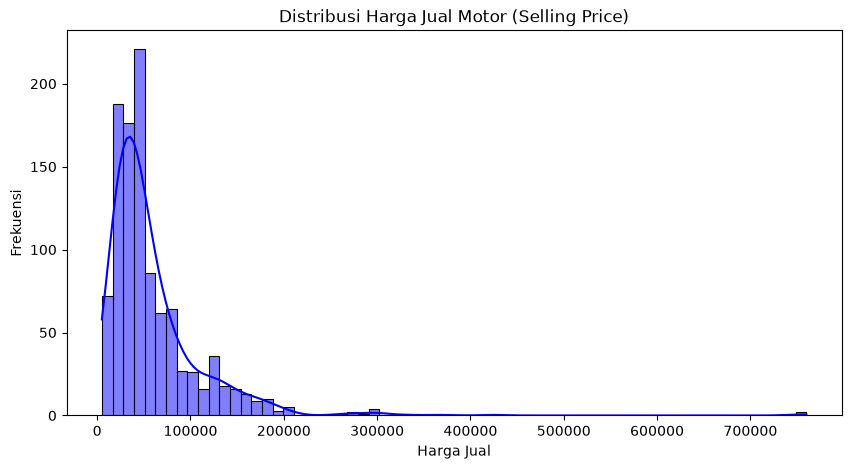

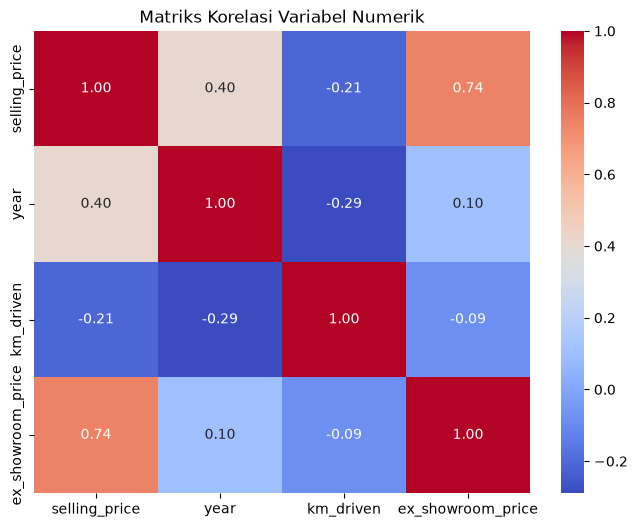

In [11]:
plt.figure(figsize=(10, 5))
sns.histplot(df['selling_price'], kde=True, color='blue')
plt.title('Distribusi Harga Jual Motor (Selling Price)')
plt.xlabel('Harga Jual')
plt.ylabel('Frekuensi')
plt.show()

# Korelasi antar variabel numerik
plt.figure(figsize=(8, 6))
sns.heatmap(df[['selling_price', 'year', 'km_driven', 'ex_showroom_price']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriks Korelasi Variabel Numerik')
plt.show()

In [12]:
# Memisahkan Fitur (X) dan Target (y)
X = df_model.drop(columns=['selling_price'])
y = df_model['selling_price']

# Membagi data training (80%) dan testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Jumlah data latih: {X_train.shape[0]} baris")
print(f"Jumlah data uji: {X_test.shape[0]} baris")

Jumlah data latih: 848 baris
Jumlah data uji: 213 baris


In [13]:
# Inisialisasi dan latih model Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print("Model berhasil dilatih!")

Model berhasil dilatih!


In [14]:
# Prediksi data test
y_pred = rf_model.predict(X_test)

# Menghitung metrik evaluasi
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("=== HASIL EVALUASI MODEL ===")
print(f"MAE  (Mean Absolute Error) : Rp {mae:,.2f}")
print(f"RMSE (Root Mean Squared Error): Rp {rmse:,.2f}")
print(f"R2 Score (Akurasi Model)     : {r2:.4f} ({r2*100:.2f}%)")

=== HASIL EVALUASI MODEL ===
MAE  (Mean Absolute Error) : Rp 12,692.93
RMSE (Root Mean Squared Error): Rp 19,277.08
R2 Score (Akurasi Model)     : 0.8591 (85.91%)


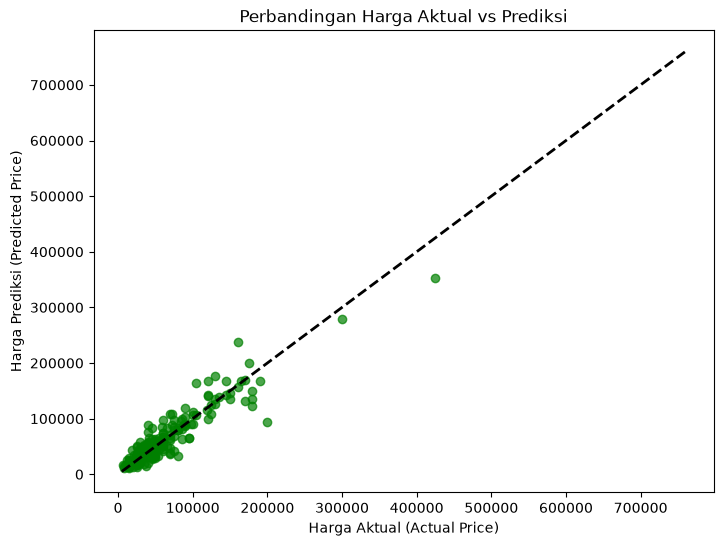

In [15]:
# Visualisasi Prediksi vs Nilai Aktual
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='green')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2)
plt.xlabel('Harga Aktual (Actual Price)')
plt.ylabel('Harga Prediksi (Predicted Price)')
plt.title('Perbandingan Harga Aktual vs Prediksi')
plt.show()

In [16]:
import joblib
joblib.dump(rf_model, 'model_prediksi_motor.pkl')

['model_prediksi_motor.pkl']